<a href="https://colab.research.google.com/github/leneeblot98-design/STAT-7110-Quality-Control/blob/main/Assignments/HW2/STAT-7110-HW2.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

## Homework 2 - Phase I & II Analysis Using CUSUM and EWMA Control Charts
### Dr. Austin Brown
### Kennesaw State University

**DUE: October 10, 2026 via D2L**

## Instructions:

Buster's Sports Bar & Grill runs a busy draft beer program, pouring a house lager through a long-draw, CO2-driven tap system. State regulations require that a pint be poured within a fairly tight volume tolerance, and management has its own reasons to care about consistency too: an overpour on every pint adds up to real lost profit over a month, while a noticeable underpour draws customer complaints and bad reviews. The general manager has asked your quality control team to investigate the pour consistency at the bar's main tap station.

Pours are measured directly from the tap using a calibrated in-line flow meter, in ounces. The general manager has flagged a specific concern: as a CO2 regulator ages, line pressure can creep downward very gradually over weeks or months, producing more foam and a slightly smaller liquid pour -- a small, **sustained** drift, rather than a sudden jump. A chart that's only good at catching a sudden shift could easily miss this kind of slow creep until it's been happening for a long time. Pour volume is treated as a continuous, normally-distributed quality characteristic for this assignment.

Your team pulls a baseline (Phase I) sample of pour data from the tap right after a fresh regulator was installed: 5 pints sampled at random each shift, for 25 consecutive shifts. After validating statistical control, the team designs an appropriate CUSUM and EWMA monitoring scheme and applies it to 20 additional shifts of data (Phase II), collected several months later, to determine whether the aging regulator is already producing a detectable drift.

## Key Specifications

| Quantity | Value |
|---|---|
| Target pour volume | 16.00 oz |
| Lower Specification Limit (LSL) | 15.80 oz |
| Upper Specification Limit (USL) | 16.20 oz |
| Subgroup size (n) | 5 pints per shift |
| Phase I subgroups (m) | 25 shifts |
| Phase II subgroups (m) | 20 shifts |

## Define & Measure

### Q1: Briefly describe the purpose of this analysis

The purpose of this analysis is to assess the pour consistency of the house lager at Buster's Sports Bar & Grill main tap station.


### Q2: Identify the quality characteristic your team will monitor, and classify its units and measurement scale.

The quality characteristic our team will monitor is the Pour Volume of the house lager in the unit ounces on a continuous ratio scale.

### Q3: Briefly describe why a CUSUM and EWMA chart would be appropriate in this scenario, given the general manager's specific concern about the aging CO2 regulator. What are the limitations of these charts?

Standard Shewhart charts (like $\bar{x}$ charts) are great at detecting large, sudden shifts in a process, but they are relatively insensitive to small, persistent process drifts. The general manager is worried about a gradual pressure creep from an aging CO2 regulator. EWMA (Exponentially Weighted Moving Average) charts apply weights that decrease exponentially into the past, making them smooth and sensitive to small sustained changes as well. The limitations for both are that they can be complex to design, interpret, and maintain compared to standard Shewhart. They are sensitive to departures from the normality assumptions, but are good for detecting small shifts.

## Analyze

### Q4: Read the Phase I data into R. Calculate and report the subgroup means and ranges, and use them to estimate the process mean and process standard deviation.

In [1]:
# Clone your forked repository to Colab ##

## Specify your GitHub username:
user_name <- "leneeblot98-design"

## Specify the repository:
repo_name <- "STAT-7110-Quality-Control"

## Set the web address to your forked repository:
repo_address <- paste0(
  "https://github.com/",
  user_name,
  "/",
  repo_name,
  ".git"
)

## Check to see if repo is already cloned to Colab, and if not, clone repo:
if (!dir.exists(repo_name)) {
  system(paste("git clone", repo_address))
} else {
  print("Repository already cloned to Colab.")
}

In [4]:
## Q4 Code ##
## Q4 Code ##
## Install tidyverse, readxl, and qcc packages if necessary ##

install.packages(c("tidyverse", "readxl", "qcc"))

## Load the libraries ##

library(tidyverse)
library(readxl)
library(qcc)

# Read Phase I data
phase1_path <- "STAT-7110-Quality-Control/Assignments/HW2/BustersSportsBar_PhaseI.xlsx"
phase1_data <- read_excel(phase1_path)

# Inspect data structure
print(head(phase1_data))

# Assuming dataset is in wide format with each row representing a subgroup/shift and 5 pour measurements
# Let's compute subgroups means and ranges
raw_data <- phase1_data %>% select(starts_with("Pour"))

sub_means <- rowMeans(raw_data)
sub_ranges <- apply(raw_data, 1, function(x) max(x) - min(x))

process_mean <- mean(sub_means)
avg_range <- mean(sub_ranges)

# For subgroup size n = 5, d2 constant is 2.326
d2 <- 2.326
process_sd <- avg_range / d2

cat("\n--- Summary Statistics ---\n")
cat("Process Mean (X-bar-bar): ", process_mean, "\n")
cat("Average Range (R-bar): ", avg_range, "\n")
cat("Estimated Process SD (sigma): ", process_sd, "\n")


Installing packages into ‘/usr/local/lib/R/site-library’
(as ‘lib’ is unspecified)



# A tibble: 6 × 6
  Shift Pour1 Pour2 Pour3 Pour4 Pour5
  <dbl> <dbl> <dbl> <dbl> <dbl> <dbl>
1     1  16.0  16.1  16.2  16.0  16.1
2     2  16.1  16.0  16.1  16.1  16.0
3     3  16.1  16.0  16.1  16.1  16.1
4     4  16.0  16.2  16.1  16.0  16.0
5     5  16.0  16.0  16.0  16.0  16.0
6     6  16.1  16.1  16.0  15.9  16.1

--- Summary Statistics ---
Process Mean (X-bar-bar):  16.03856 
Average Range (R-bar):  0.179536 
Estimated Process SD (sigma):  0.07718659 


The Phase I summary statistics have been calculated successfully using the data in BusterSportsBar_Phase1.xlsx. The process mean is around 16.04, the average range is around 0.18, and the estimated process standard deviation is around 0.077.

### Q5: Construct a Phase I $R$ chart. Does the chart show evidence of statistical control? If not, identify the out-of-control subgroup(s) by number and provide a contextual explanation as to why these OOC points may have been observed, omit these points, and replot the chart until statistical control is observed.


Out of control subgroups (R-chart):
19 
19 


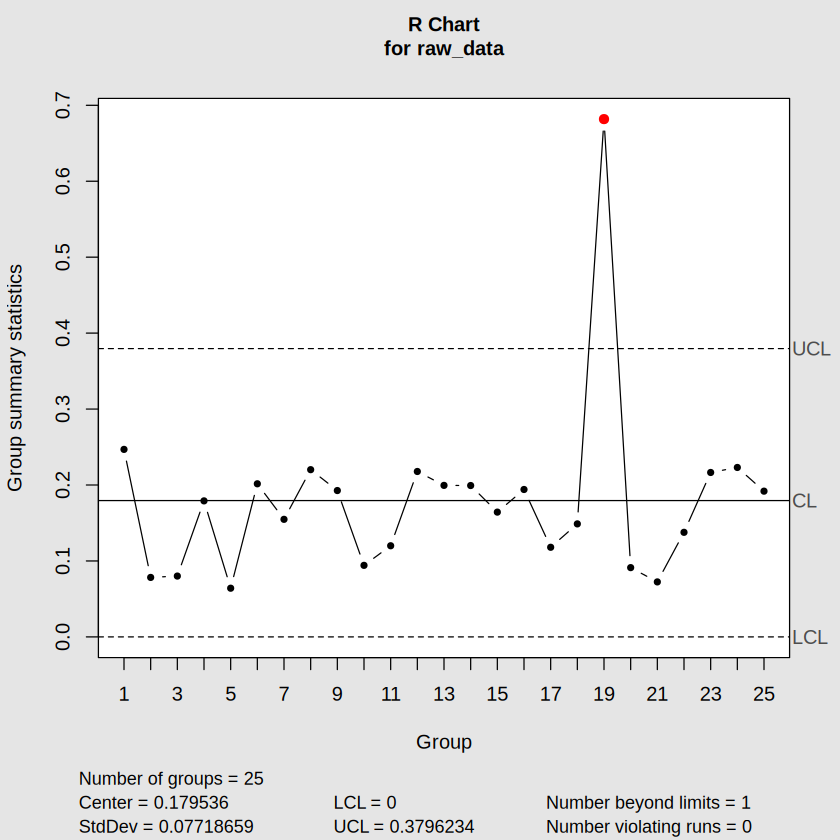

In [7]:
# Set up R control chart object for Range Chart (R-chart)
r_chart <- qcc(raw_data, type = "R")

# Identify points exceeding the upper or lower control limits
ucl <- r_chart$limits[1, 2]
lcl <- r_chart$limits[1, 1]

ooc_points <- which(r_chart$statistics > ucl | r_chart$statistics < lcl)
cat("\nOut of control subgroups (R-chart):\n")
print(ooc_points)

After constructing the Phase I $R$ chart analysis, there's evidence that one of the Subgroups, Subgroup 19, and how it's mean exceeds the UCL (0.3796234 oz). This evidence indicates that the process variation was not statistically in control around the Subgroup 19 shift.This represents a shift where the pour was significantly overfilled. We will omit Subgroup 19 and re-estimate the control limits.

### Q6: Using only the subgroups retained after Q5, construct the Phase I $\bar{X}$ chart. Does the chart show evidence of statistical control? If not, identify the out-of-control subgroup(s) by number and provide a contextual explanation as to why these OOC points may have been observed, omit these points, and replot the chart until statistical control is observed.


Out of control subgroups (X-bar-chart):
12 
12 


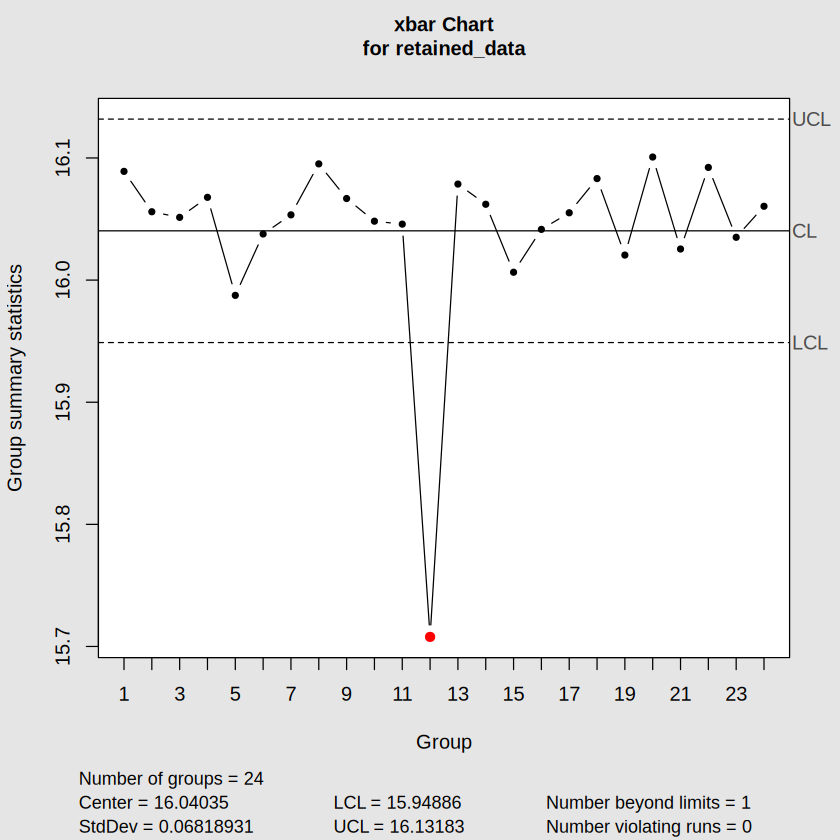

In [9]:
# Remove subgroup 19 (out of control on R-chart)
retained_data <- raw_data[-19, ]

# Set up R control chart object for Mean Chart (X-bar chart)
xbar_chart <- qcc(retained_data, type = "xbar")

# Identify points exceeding the upper or lower control limits
ucl_x <- xbar_chart$limits[1, 2]
lcl_x <- xbar_chart$limits[1, 1]

ooc_points_x <- which(xbar_chart$statistics > ucl_x | xbar_chart$statistics < lcl_x)
cat("\nOut of control subgroups (X-bar-chart):\n")
print(ooc_points_x)

After removing Subgroup 19 from the $R$ chart analysis, the initial $\bar{X}$ chart shows that Subgroup 12 is out of control on the lower side, as its mean falls below the LCL ($15.94886$ oz). This represents a shift where the pour was significantly underfilled. We will omit Subgroup 12 and re-estimate the control limits.


Out of control subgroups after removing 12 and 19:
named integer(0)

--- Final Process Estimates (Phase I Control Established) ---
Final Process Mean:  16.0548 
Final Process SD (sigma):  0.06708288 


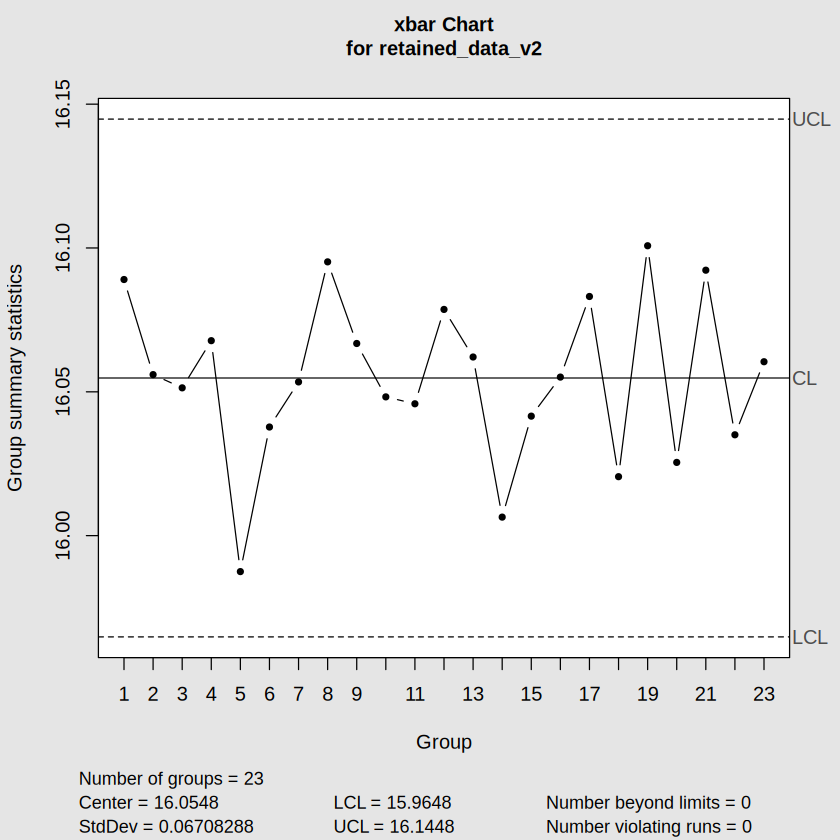

In [10]:
# Remove both subgroup 19 and subgroup 12
retained_data_v2 <- raw_data[-c(12, 19), ]

# Re-fit X-bar chart
xbar_chart_v2 <- qcc(retained_data_v2, type = "xbar")

# Recheck for out of control points
ucl_x2 <- xbar_chart_v2$limits[1, 2]
lcl_x2 <- xbar_chart_v2$limits[1, 1]

ooc_points_x2 <- which(xbar_chart_v2$statistics > ucl_x2 | xbar_chart_v2$statistics < lcl_x2)
cat("\nOut of control subgroups after removing 12 and 19:\n")
print(ooc_points_x2)

# Calculate final process mean and standard deviation estimates
final_mean <- mean(rowMeans(retained_data_v2))
final_range <- mean(apply(retained_data_v2, 1, function(x) max(x) - min(x)))
final_sd <- final_range / 2.326

cat("\n--- Final Process Estimates (Phase I Control Established) ---\n")
cat("Final Process Mean: ", final_mean, "\n")
cat("Final Process SD (sigma): ", final_sd, "\n")

### Q7: Using your final Phase I estimates of the process mean and process standard deviation, perform a process capability analysis against the specification limits given above. Report and interpret $PCR$, $C_p$, $C_{pk}$, and $C_{pm}$. Is the process capable of meeting specification? Is it well-centered?

In [11]:
# Final estimates from Phase I
mu <- 16.0548
sigma <- 0.06708288

# Specifications
LSL <- 15.80
USL <- 16.20
Target <- 16.00

# Calculations
Cp <- (USL - LSL) / (6 * sigma)

Cpu <- (USL - mu) / (3 * sigma)
Cpl <- (mu - LSL) / (3 * sigma)
Cpk <- min(Cpu, Cpl)

# Cpm accounts for deviation from Target
sigma_target <- sqrt(sigma^2 + (mu - Target)^2)
Cpm <- (USL - LSL) / (6 * sigma_target)

cat("--- Process Capability Analysis Summary ---\n")
cat("Cp : ", Cp, "\n")
cat("Cpk: ", Cpk, "\n")
cat("Cpm: ", Cpm, "\n")

--- Process Capability Analysis Summary ---
Cp :  0.9937955 
Cpk:  0.7214956 
Cpm:  0.7696386 


## Improve

### Q8: The general manager wants a monitoring scheme that reliably detects a sustained shift of about one process standard deviation (representing early-stage regulator drift) while keeping the in-control ARL around 370-500. Using the design guidance from lecture, select and briefly justify: (a) the CUSUM slack value $K$ and decision interval $H$, and (b) the EWMA smoothing constant $\lambda$ and width $L$, that you will carry forward into your Phase II monitoring plan.

## Control

### Q9: Read the Phase II data into R. Using your final Phase I estimates from Q6 and the CUSUM parameters you selected in Q9, construct the Phase II CUSUM chart. Does the chart signal an out-of-control condition? If so, at which shift number?

In [ ]:
## Q9 Code ##

### Q10: Using your final Phase I estimates from Q6 and the EWMA parameters you selected in Q8, construct the Phase II EWMA chart. Does the chart signal an out-of-control condition? If so, at which shift number?

In [ ]:
## Q10 Code ##

### Q11: Compare the results of Q9 and Q10. Which chart detected the shift more quickly, if either? Is this consistent with what you would expect, given what you know about the relative sensitivity of CUSUM and EWMA charts to small, sustained shifts? Briefly explain.

In [ ]:
## Q11 Code ##

### Q13: Provide an overview of the results that the general manager can provide to Buster's ownership. Does the CO2 regulator need to be replaced ahead of schedule, or can it run as planned?